# 10 – Patient Explanations: Modifiable vs Fixed Risk Factors

**Goal:** Turn SHAP numbers into explanations a patient or doctor can act on.

Each risk factor is labelled as:
- **Fixed**: cannot be changed (age, sex, previous stroke)
- **Modifiable**: can be changed with lifestyle or treatment (BP, cholesterol, smoking, glucose, BMI)
- **Treatment**: current medication (BP meds)

This tells the patient *what they can do something about*, which feeds into Module 2 (recommendations).

In [9]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

SEED = 42
os.makedirs("../outputs", exist_ok=True)

# Load and clean (same steps as notebook 01)
df = pd.read_csv("../data/framingham.csv").drop_duplicates()
df.loc[(df["currentSmoker"] == 0) & (df["cigsPerDay"].isna()), "cigsPerDay"] = 0
df = df.drop(columns=["education"])

X = df.drop(columns=["TenYearCHD"])
y = df["TenYearCHD"].astype(int)

# 60 / 20 / 20 split
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_cal, X_test, y_cal, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

# Fill missing values using training data only
imputer = SimpleImputer(strategy="median").fit(X_train)
def impute(d):
    return pd.DataFrame(imputer.transform(d), columns=X.columns, index=d.index)
Xtr, Xca, Xte = impute(X_train), impute(X_cal), impute(X_test)

# XGBoost
model = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.03,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss", random_state=SEED, n_jobs=1)
model.fit(Xtr, y_train)

# Platt scaling, so risk scores are realistic percentages
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression().fit(logit(model.predict_proba(Xca)[:, 1]), y_cal)

def predict_risk(Xd):
    return platt.predict_proba(logit(model.predict_proba(Xd)[:, 1]))[:, 1]

p_test = predict_risk(Xte)
print("Test AUC:", round(roc_auc_score(y_test, p_test), 3))

Test AUC: 0.677


## Step 1 – Label every factor

Each feature gets a plain-language name, a type (fixed / modifiable / treatment) and a unit.
Yes/no features have no unit.

In [10]:
FACTORS = {
    "male":            ("Sex (male)",                   "fixed",      None),
    "age":             ("Age",                          "fixed",      "years"),
    "prevalentStroke": ("Previous stroke",              "fixed",      None),
    "BPMeds":          ("On blood pressure medication", "treatment",  None),
    "currentSmoker":   ("Current smoker",               "modifiable", None),
    "cigsPerDay":      ("Cigarettes per day",           "modifiable", "per day"),
    "prevalentHyp":    ("Hypertension",                 "modifiable", None),
    "diabetes":        ("Diabetes",                     "modifiable", None),
    "totChol":         ("Total cholesterol",            "modifiable", "mg/dL"),
    "sysBP":           ("Systolic blood pressure",      "modifiable", "mmHg"),
    "diaBP":           ("Diastolic blood pressure",     "modifiable", "mmHg"),
    "BMI":             ("Body mass index",              "modifiable", "kg/m²"),
    "heartRate":       ("Heart rate",                   "modifiable", "bpm"),
    "glucose":         ("Blood glucose",                "modifiable", "mg/dL"),
}

pd.DataFrame(FACTORS, index=["Name", "Type", "Unit"]).T

,Name,Type,Unit
male,Sex (male),fixed,NaN
age,Age,fixed,years
prevalentStroke,Previous stroke,fixed,NaN
BPMeds,On blood pressure medication,treatment,NaN
currentSmoker,Current smoker,modifiable,NaN
cigsPerDay,Cigarettes per day,modifiable,per day
prevalentHyp,Hypertension,modifiable,NaN
diabetes,Diabetes,modifiable,NaN
totChol,Total cholesterol,modifiable,mg/dL
sysBP,Systolic blood pressure,modifiable,mmHg


## Step 2 – Explain one patient

SHAP shows how much each factor pushed this patient's risk up or down.
We keep the top 5 and write them in plain language.

In [11]:
explainer = shap.TreeExplainer(model)
shap_test = explainer(Xte)

def explain_patient(i, top_n=5):
    row = Xte.iloc[i]
    t = pd.DataFrame({"feature": X.columns, "value": row.values, "shap": shap_test.values[i]})
    t["name"] = t["feature"].map(lambda f: FACTORS[f][0])
    t["type"] = t["feature"].map(lambda f: FACTORS[f][1])
    t["unit"] = t["feature"].map(lambda f: FACTORS[f][2])
    t = t.reindex(t["shap"].abs().sort_values(ascending=False).index).head(top_n)
    return float(p_test[i]), t.reset_index(drop=True)

def describe(r):
    if pd.isna(r["unit"]):
        val = "yes" if r["value"] == 1 else "no"
    else:
        val = f'{r["value"]:g} {r["unit"]}'
    direction = "raises" if r["shap"] > 0 else "lowers"
    return f'{r["name"]} ({val}) {direction} risk [{r["type"]}]'

# Highest-risk patient in the test set
i = int(np.argmax(p_test))
risk, top = explain_patient(i)

print(f"Estimated 10-year CVD risk: {risk:.0%}\n")
print("Factors you CAN change:")
for _, r in top[top["type"] != "fixed"].iterrows():
    print("  -", describe(r))
print("\nFactors you cannot change:")
for _, r in top[top["type"] == "fixed"].iterrows():
    print("  -", describe(r))

Estimated 10-year CVD risk: 49%

Factors you CAN change:
  - Blood glucose (394 mg/dL) raises risk [modifiable]
  - Systolic blood pressure (204 mmHg) raises risk [modifiable]
  - On blood pressure medication (yes) raises risk [treatment]
  - Cigarettes per day (0 per day) lowers risk [modifiable]

Factors you cannot change:
  - Age (67 years) raises risk [fixed]


## Step 3 – How much of the risk is modifiable? (whole test set)

For every patient, we add up the SHAP size of each factor type and take the average share.

fixed         39.299999
modifiable    59.200001
treatment      1.400000
dtype: float32


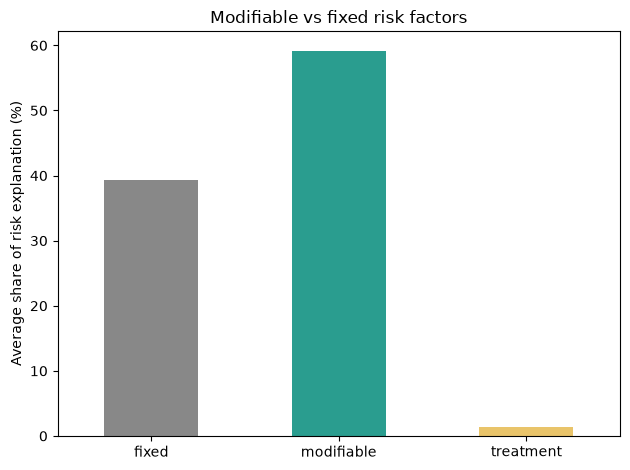

In [12]:
abs_sv = pd.DataFrame(np.abs(shap_test.values), columns=X.columns)
by_type = abs_sv.T.groupby(lambda f: FACTORS[f][1]).sum().T
share = (by_type.div(by_type.sum(axis=1), axis=0).mean() * 100).round(1)
print(share)

share.plot(kind="bar", color=["#888888", "#2a9d8f", "#e9c46a"])
plt.ylabel("Average share of risk explanation (%)")
plt.title("Modifiable vs fixed risk factors")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../outputs/modifiable_vs_fixed.png", dpi=150)
plt.show()

## Step 4 – Save the explanation (format for the Shared Patient Profile)

In [13]:
explanation = {
    "risk_score": round(risk, 3),
    "top_factors": [
        {"factor": r["name"], "value": float(r["value"]), "type": r["type"],
         "direction": "raises" if r["shap"] > 0 else "lowers",
         "impact": round(float(r["shap"]), 3)}
        for _, r in top.iterrows()
    ],
    "modifiable_share_pct": round(float(share.get("modifiable", 0)), 1),
}

with open("../outputs/patient_explanation.json", "w") as f:
    json.dump(explanation, f, indent=2)

print(json.dumps(explanation, indent=2))

{
  "risk_score": 0.493,
  "top_factors": [
    {
      "factor": "Age",
      "value": 67.0,
      "type": "fixed",
      "direction": "raises",
      "impact": 0.878
    },
    {
      "factor": "Blood glucose",
      "value": 394.0,
      "type": "modifiable",
      "direction": "raises",
      "impact": 0.78
    },
    {
      "factor": "Systolic blood pressure",
      "value": 204.0,
      "type": "modifiable",
      "direction": "raises",
      "impact": 0.644
    },
    {
      "factor": "On blood pressure medication",
      "value": 1.0,
      "type": "treatment",
      "direction": "raises",
      "impact": 0.225
    },
    {
      "factor": "Cigarettes per day",
      "value": 0.0,
      "type": "modifiable",
      "direction": "lowers",
      "impact": -0.164
    }
  ],
  "modifiable_share_pct": 59.2
}


## Summary
- Each risk factor is labelled as fixed, modifiable or treatment.
- About 59% of the model's risk explanation comes from factors patients can change.
- The JSON output is the format other modules will read (Shared Patient Profile).